# Misalignment and optics along a tracked orbit

Suppose a beam position monitor sees the orbit move after a quadrupole shifts sideways. Has the focusing changed too? In this tutorial we can answer that question by switching a downstream sextupole off and on. We will use the same 3 m beamline to see what happens when the quadrupole rolls about its axis.

## Which axis does the particle see?

The lattice defines a **design trajectory** and a transverse survey plane at each position $s$. Tracking reports the particle in these coordinates. A magnet installed with offsets `dx` and `dy` has its magnetic axis at $(d_x,d_y)$ in the local plane, in metres. A design roll `tilt` and an additional mechanical roll `dtilt` are specified in radians.

For a straight magnet, let $\theta=\mathrm{tilt}+\mathrm{dtilt}$. A positive roll turns the magnet's horizontal axis towards the survey $+y$ axis. The coordinates of the **same particle** in the magnet are

$$
\begin{pmatrix}x_m\\y_m\end{pmatrix}
=
\begin{pmatrix}\cos\theta & \sin\theta\\-\sin\theta & \cos\theta\end{pmatrix}
\begin{pmatrix}x-d_x\\y-d_y\end{pmatrix}.
$$

For example, a particle at $x=0$ enters an unrolled quadrupole displaced to the right at $x_m=-d_x$. The tracker evaluates the field in the magnet frame and returns the outgoing particle to survey coordinates. Its kick comes from the field it sampled. The change of coordinates by itself gives no magnetic kick.

In a bend, the entrance and exit planes already have different orientations. A mechanical roll about the displaced entrance axis also moves and tips the physical exit face. Ocelot accounts for the flight from that face to the survey plane, including the change in arrival time. The offsets of a sector bend are defined in the local transverse axes at each face.

## An aligned beamline

A focusing quadrupole **Q** is followed by a drift, a thin normal sextupole **S**, and a drift to the observation point. Start with both magnets centred and the sextupole switched off. The launch is on axis at 1 GeV with zero transverse momenta. The variable `tws0` holds the Twiss parameters at the beamline entrance ($s=0$). The horizontal and vertical beta and alpha functions there specify the initial beam ellipse in each plane. We use geometric emittances in m rad and zero dispersion. Run the cells in order to follow successive changes to Q and S.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

import ocelot as ocl

entrance = ocl.Drift(l=0.30, eid="D1")
quad = ocl.Quadrupole(l=0.30, k1=2.0, eid="Q")  # k1 in m^-2
to_sext = ocl.Drift(l=1.00, eid="D2")
sext = ocl.Multipole(kn=[0., 0., 0.], eid="S")
to_screen = ocl.Drift(l=1.40, eid="D3")
line = ocl.MagneticLattice([entrance, quad, to_sext, sext, to_screen])

tws0 = ocl.Twiss(E=1.0, beta_x=2.0, alpha_x=-1.0, beta_y=2.0, alpha_y=0.5,
                 emit_x=2.0e-9, emit_y=0.5e-9)
s_sext = entrance.l + quad.l + to_sext.l

`lattice_track` advances one `Particle` and returns its coordinates at the entrance and each element exit. Give it a fresh particle for each launch. Alongside the orbit, plot the horizontal rms betatron size $\sigma_x=\sqrt{\varepsilon_x\beta_x}$ from ordinary `twiss`. The band shows how much a beam can expand or contract even when its centre stays fixed.

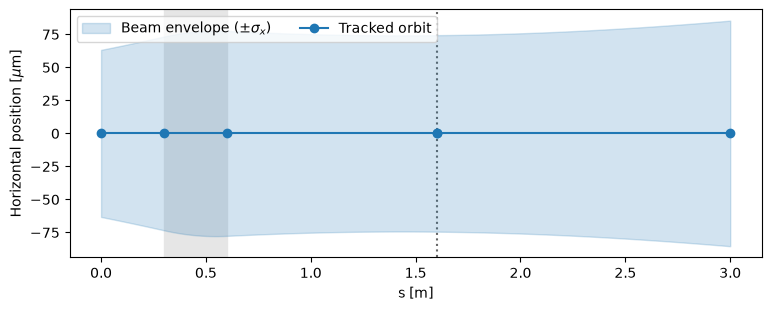

In [2]:
quad.dx, quad.dtilt = 0., 0.
sext.kn = np.zeros(3)
aligned = ocl.lattice_track(line, ocl.Particle(E=tws0.E))
s_exit = [p.s for p in aligned]
design = ocl.twiss(line, tws0, nPoints=151, return_df=True)
sigma_x = np.sqrt(design.emit_x * design.beta_x)

def mark_magnets(ax):
    ax.axvspan(entrance.l, entrance.l + quad.l, color="0.90", zorder=0)
    ax.axvline(s_sext, color="0.4", linestyle=":", zorder=0)

fig, ax = plt.subplots(figsize=(7.6, 3.0), layout="constrained")
mark_magnets(ax)
ax.fill_between(design.s, -1e6 * sigma_x, 1e6 * sigma_x,
                color="C0", alpha=0.20, label=r"Beam envelope ($\pm\sigma_x$)")
ax.plot(s_exit, [1e6 * p.x for p in aligned], "o-", color="C0", label="Tracked orbit")
ax.set(xlabel="s [m]", ylabel=r"Horizontal position [$\mu$m]")
ax.legend(loc="upper left", ncols=2)
plt.show()

The dots stay on the survey axis through Q (grey band) and S (dotted line). The changing width comes from the initial beam ellipse, quadrupole and drifts. The dots mark observations at element boundaries. The thin sextupole has coincident entrance and exit positions.

## Moving the quadrupole

Shift Q by $+1$ mm horizontally, leaving the particle launch unchanged. In the magnet frame the particle enters to the left of a horizontally focusing quadrupole, so we expect a kick towards $+x$. Repeat with a positive mechanical roll of 150 mrad. This deliberately large angle makes the vertical response visible. In both runs the sextupole stays off.

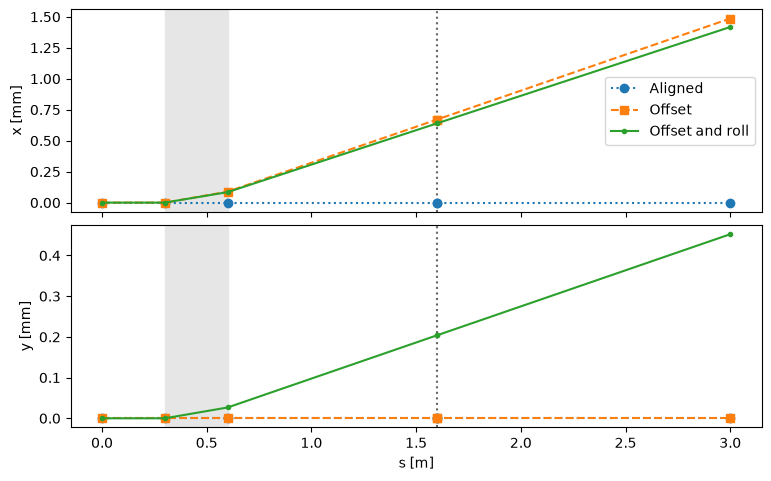

In [3]:
quad.dx, quad.dtilt = 1e-3, 0.
sext.kn = np.zeros(3)
offset = ocl.lattice_track(line, ocl.Particle(E=tws0.E))
quad.dtilt = 0.150
offset_rolled = ocl.lattice_track(line, ocl.Particle(E=tws0.E))

fig, (ax_x, ax_y) = plt.subplots(2, 1, sharex=True, figsize=(7.6, 4.7), layout="constrained")
for samples, label, style in [(aligned, "Aligned", "o:"),
                              (offset, "Offset", "s--"),
                              (offset_rolled, "Offset and roll", ".-")]:
    ax_x.plot(s_exit, [1e3 * p.x for p in samples], style, label=label)
    ax_y.plot(s_exit, [1e3 * p.y for p in samples], style)
for ax in (ax_x, ax_y):
    mark_magnets(ax)
ax_x.set(ylabel="x [mm]")
ax_y.set(xlabel="s [m]", ylabel="y [mm]")
ax_x.legend()
plt.show()

With the offset alone, the orbit moves only horizontally. Rolling the displaced Q turns part of the steering into the vertical plane. Downstream of Q both coordinates then grow linearly with distance. The lines inside Q join the element-face observations.

We can check the horizontal sign and magnitude independently. For a constant positive $k_1$, the magnet-frame orbit obeys $x_m''+k_1 x_m=0$. The launch $x_m=-d_x$, $x_m'=0$ gives $x'_{\rm exit}=d_x\sqrt{k_1}\sin(\sqrt{k_1}L_Q)$. Here the on-momentum, paraxial slope equals the normalized transverse momentum used by the linear map.

In [4]:
quad_exit = offset[2]  # after D1 and Q
predicted_px = quad.dx * np.sqrt(quad.k1) * np.sin(np.sqrt(quad.k1) * quad.l)
print(f"Q exit momentum with the offset alone = {1e3 * quad_exit.px:.6f} mrad, "
      f"hard-edge prediction {1e3 * predicted_px:.6f} mrad")
np.testing.assert_allclose(quad_exit.px, predicted_px, rtol=1e-12)

Q exit momentum with the offset alone = 0.582161 mrad, hard-edge prediction 0.582161 mrad


## Does steering change the beta functions?

Keep the offset, remove the roll, and leave S off for a control calculation. In this linear model the displaced quadrupole has a map $F(z)=Rz+b$. The offset supplies a steering term $b$. Two particles separated by $u$ leave separated by $Ru$, independent of $b$.

Call `twiss(line, tws0)` to use the elements' first-order design maps. Pass `reference_orbit=ocl.Particle()` to track a zero-coordinate launch at the beam energy `tws0.E` through the active tracking maps. At each map entrance Ocelot evaluates the Jacobian $J=\partial F/\partial z$ on that orbit and uses it to transport small deviations. The returned `x` and `y` then follow the reference particle. Compare the two beta functions over the whole line.

In [5]:
quad.dx, quad.dtilt = 1e-3, 0.
sext.kn = np.zeros(3)
design = ocl.twiss(line, tws0, nPoints=151, return_df=True)
linear = ocl.twiss(line, tws0, reference_orbit=ocl.Particle(), nPoints=151, return_df=True)
betas = ["beta_x", "beta_y"]
max_difference = np.abs(linear[betas] - design[betas]).to_numpy().max()
print(f"Exit orbit x = {1e3 * linear.x.iloc[-1]:.3f} mm")
print(f"Largest beta difference with S off = {max_difference:.2e} m")
np.testing.assert_allclose(linear[betas], design[betas], rtol=0., atol=1e-11)
np.testing.assert_allclose(linear.x.iloc[-1], offset[-1].x, rtol=1e-12)

Exit orbit x = 1.486 mm
Largest beta difference with S off = 3.55e-15 m


The exit orbit moved by about 1.49 mm while both beta functions agreed to roundoff. Now power S. The `kn[2]` entry of a thin `Multipole` is the integrated sextupole strength $K_2 L$ in m$^{-2}$. On the horizontal midplane its kick and the gradient of that kick are

$$
\Delta p_x=-\tfrac12 K_2 L\,x^2,\qquad
\left.\frac{\partial \Delta p_x}{\partial x}\right|_{x_r}=-K_2 L\,x_r .
$$

The steered particle reaches S at $x_r>0$. Nearby particles see a **quadrupole** of inverse focal length $k=K_2 L\,x_r$, focusing horizontally and defocusing vertically. This lower-order field sampled on a displaced orbit is called *feed-down*. On the design axis the sextupole gradient is zero. Plot the optics calculated about the two trajectories.

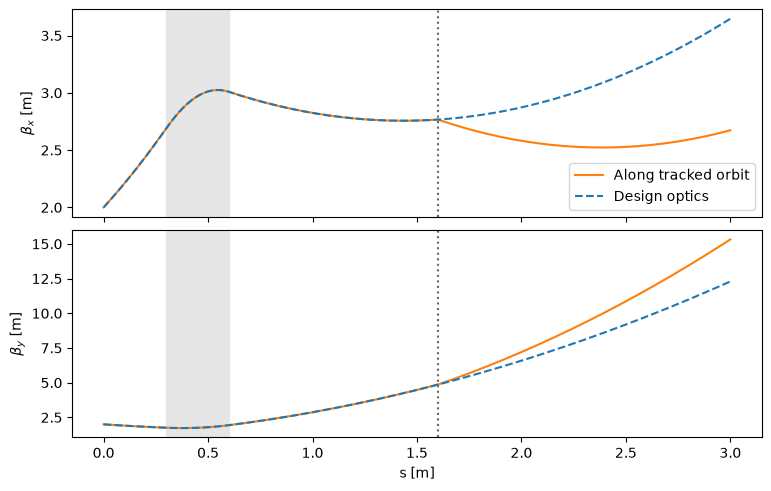

In [6]:
quad.dx, quad.dtilt = 1e-3, 0.
k2l = 200.0  # m^-2
sext.kn = np.array([0., 0., k2l])
design = ocl.twiss(line, tws0, nPoints=151, return_df=True)
tracked = ocl.twiss(line, tws0, reference_orbit=ocl.Particle(), nPoints=151, return_df=True)

fig, axes = plt.subplots(2, 1, sharex=True, figsize=(7.6, 4.8), layout="constrained")
for ax, quantity, label in zip(axes, betas, [r"$\beta_x$ [m]", r"$\beta_y$ [m]"]):
    mark_magnets(ax)
    ax.plot(tracked.s, tracked[quantity], color="C1", label="Along tracked orbit")
    ax.plot(design.s, design[quantity], "--", color="C0", label="Design optics")
    ax.set(ylabel=label)
axes[0].legend()
axes[1].set(xlabel="s [m]")
plt.show()

Both curves coincide up to S. The thin lens changes the angular spread and position–momentum correlation there. The beta functions are continuous at S and separate in the final drift. At the screen the tracked beam has a smaller horizontal beta and a larger vertical beta.

A local check distinguishes the kick to the reference particle from the focusing of its neighbours. At S the orbit momentum changes by $-K_2L\,x_r^2/2$, while the beam ellipses obey $\Delta\alpha_x=k\beta_x$ and $\Delta\alpha_y=-k\beta_y$. Omit `nPoints` to get samples at map boundaries. The exits of D2 and S then give the two sides of the thin lens.

In [7]:
faces = ocl.twiss(line, tws0, reference_orbit=ocl.Particle(), return_df=True).set_index("id")
before, after = faces.loc["D2"], faces.loc["S"]
k = k2l * before.x
print(f"At S, x = {1e3 * before.x:.3f} mm, effective 1/f = {k:.4f} m^-1")
print(f"Reference kick = {1e6 * (after.xp - before.xp):.2f} µrad")
print(f"At the screen, beta_x = {tracked.beta_x.iloc[-1]:.2f} m, "
      f"beta_y = {tracked.beta_y.iloc[-1]:.2f} m")
np.testing.assert_allclose(after.xp - before.xp, -0.5 * k2l * before.x**2, rtol=1e-12)
np.testing.assert_allclose([after.alpha_x - before.alpha_x, after.alpha_y - before.alpha_y],
                           [k * before.beta_x, -k * before.beta_y], rtol=1e-12)

At S, x = 0.671 mm, effective 1/f = 0.1342 m^-1
Reference kick = -45.00 µrad
At the screen, beta_x = 2.67 m, beta_y = 15.32 m


## A roll can couple a centred beam

Switch S off and centre Q again. A centred, on-axis particle sees zero quadrupole field for **any** roll. At 150 mrad the field has both normal and skew quadrupole components in the survey axes. The skew component makes a horizontal displacement produce a vertical kick and vice versa. The beam can therefore change shape around a stationary centre.

For this open beamline, `twiss` transports the transverse betatron covariance $\Sigma$ in $(x,p_x,y,p_y)$. In each plane the reported emittance and beta describe the projected ellipse, e.g. $\varepsilon_x=\sqrt{\det\Sigma_{(x,p_x)}}$ and $\beta_x=\Sigma_{xx}/\varepsilon_x$. We supplied both entrance emittances, so the relative populations of the two planes are specified. Compare their horizontal–vertical position correlation $\rho_{xy}=\langle (x-\bar x)(y-\bar y)\rangle/(\sigma_x\sigma_y)$ for zero and finite roll.

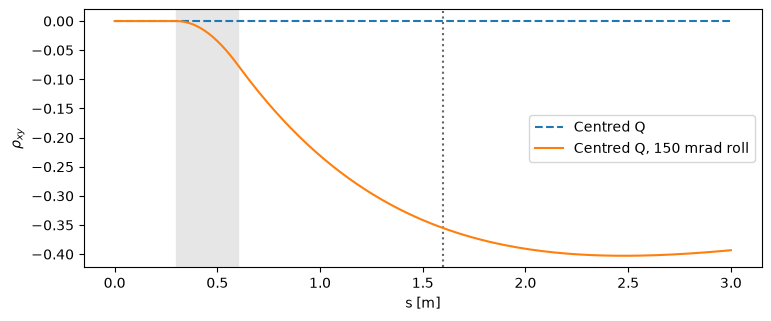

In [8]:
sext.kn = np.zeros(3)
quad.dx = 0.
fig, ax = plt.subplots(figsize=(7.6, 3.1), layout="constrained")
mark_magnets(ax)
for roll, label, style in [(0., "Centred Q", "--"), (0.150, "Centred Q, 150 mrad roll", "-")]:
    quad.dtilt = roll
    optics = ocl.twiss(line, tws0, nPoints=151, return_df=True)
    rho_xy = optics.xy / np.sqrt(optics.xx * optics.yy)
    ax.plot(optics.s, rho_xy, style, label=label)

    orbit = ocl.lattice_track(line, ocl.Particle(E=tws0.E))
    np.testing.assert_allclose([[p.x, p.y] for p in orbit], 0., atol=1e-15)
    if roll == 0.:
        np.testing.assert_allclose(rho_xy, 0., atol=1e-14)

ax.set(xlabel="s [m]", ylabel=r"$\rho_{xy}$")
ax.legend()
plt.show()

The unrolled line keeps the two initially independent planes uncorrelated. With the roll, the correlation develops inside Q and evolves in the drift as the transverse momenta contribute to the positions. Both reference particles still reach the screen at $x=y=0$. A beam position monitor measuring only the centroid would miss this change.

## Taking this to another lattice

- Use `dx` and `dy` in metres to move the magnetic axis. Use `tilt` for its design orientation and `dtilt` for an installation roll in radians. For many randomly displaced magnets, `errors_seed` in `ocelot.cpbd.errors` applies a draw and returns the lattice and its alignment records. Pass the records to `apply_alignment_errors` to reproduce that draw.
- Use `lattice_track(line, particle)` for a single-particle trajectory. `Particle.px` and `Particle.py` are momenta divided by the reference momentum. Orbit-based Twiss samples report these same quantities as `xp` and `yp`. They approximate slopes in the on-momentum, small-angle examples here.
- For optics around a known launch, use `twiss(line, tws0, reference_orbit=particle)`. Choose a tracking map that includes the field you want to sample. The thin `Multipole` used here includes the sextupole kick. For a thick `Sextupole`, one option is `method={ocl.Sextupole: ocl.SecondTM}` when constructing the lattice. The resulting Twiss functions describe small deviations around the chosen orbit. Track a distribution to study finite-amplitude distortion.
- In a stable, fixed-momentum magnetic ring, `periodic_twiss(ring, ring_beam, reference_orbit="closed")` finds the transverse closed orbit and matches the two normal modes there. Here `ring_beam` is a `Twiss` object supplying the beam energy and the geometric emittance of each mode. The ring determines the matched optics. The returned beta functions and emittances describe the projected beam ellipse in each physical plane.

Short scripts for trying the calculations independently are [displaced-quadrupole tracking](../ebeam/misaligned_quadrupole.py), [sextupole feed-down](../ebeam/off_axis_sextupole_optics.py), and [matched optics in a coupled FODO ring](../ebeam/coupled_fodo_optics.py).